# CodeAhimsa: the Socratic guardrail, step by step

**Decision pattern:** #guardrails · #strands-decider-2b

CodeAhimsa is a coding tutor that refuses to hand over the answer. Amazon Bedrock writes every reply, and **Strands Decider 2B** decides, before the student sees it, whether the reply spoils the exercise.

This notebook walks through that decision:

1. The two typed questions Decider answers
2. Asking Decider about a spoiler and a hint (live)
3. Turning scores into a verdict (the policy)
4. The full agent: eager tutor with and without the guardrail (live, needs Bedrock)
5. Evaluation: Decider 2B vs. a Bedrock LLM judge on 16 labeled replies

Demo video: https://youtu.be/l1YLZODMKss · Repo: https://github.com/Pratheeksh-7S/codeahimsa

**To run the live cells**, from the repo root:

```bash
pip install -r requirements.txt
strands-decider serve StrandsAgents/strands-decider-2B-qwen3.5-v1-2610 --port 8099   # separate terminal
```
Step 4 also needs Bedrock credentials (for example `AWS_BEARER_TOKEN_BEDROCK` and `AWS_REGION`). Step 5 works offline.

In [1]:
import os, sys
ROOT = ".." if os.path.isdir("../patterns") else "."   # works from the repo root or notebooks/
sys.path.insert(0, os.path.abspath(ROOT))
from patterns.socratic_guardrail import QUESTIONS, DeciderClient, build_state
from patterns.socratic_guardrail.questions import SPOIL_BLOCK, GROUNDED_MIN

## 1. The two typed questions

Decider 2B answers typed questions instead of free text. Both of ours are `noul` (yes/no), so each answer is a probability of "yes".

In [2]:
for name, q in QUESTIONS.items():
    print(f"{name:16s} [{q['type']}]  {q['instructions']}")
print(f"\nPolicy: block if spoils_solution >= {SPOIL_BLOCK}, or grounded < {GROUNDED_MIN}")

spoils_solution  [noul]  Does the tutor reply contain a complete, ready-to-paste solution instead of a hint?
grounded         [noul]  Is the tutor reply grounded in what the student actually asked?

Policy: block if spoils_solution >= 0.6, or grounded < 0.3


## 2. Ask Decider about a spoiler and a hint (live)

The state is two lines: what the student asked, and what the tutor is about to send. On a laptop CPU each call takes about 2 seconds.

In [ ]:
decider = DeciderClient()
student = "How do I reverse a list in Python? Just give me the full code."
replies = {
    "spoiler": "Here you go:\n\ndef reverse(lst):\n    return lst[::-1]\n\nJust copy this.",
    "hint":    "Think about slicing. What do you think a step of -1 would do to a list?",
}
scores = {}
for label, reply in replies.items():
    answers, ms = decider.ask(build_state(student, reply), QUESTIONS)
    scores[label] = {k: v["noul"] for k, v in answers.items()}
    print(f"{label:8s} spoils={scores[label]['spoils_solution']:.2f}  grounded={scores[label]['grounded']:.2f}  ({ms:.0f} ms)")

## 3. From scores to a verdict

This is the same rule the `SocraticGuardrail` intervention handler applies before every `send_to_student` tool call. `guide_*` verdicts send the model back with feedback (`Guide`); after two failed rewrites the handler swaps in a safe fallback reply (`Transform`), so it fails closed.

In [ ]:
def verdict(spoils: float, grounded: float) -> str:
    if spoils >= SPOIL_BLOCK:
        return "guide_hint      -> blocked, model told to rewrite as a hint"
    if grounded < GROUNDED_MIN:
        return "guide_on_topic  -> blocked, model told to answer the actual question"
    return "proceed         -> student sees the reply"

for label, s in scores.items():
    print(f"{label:8s} {verdict(s['spoils_solution'], s['grounded'])}")

## 4. The full agent: eager tutor, without and with the guardrail (live, needs Bedrock)

`eager=True` swaps in a plain "helpful assistant" prompt that hands over full code, so we can see what the guardrail catches when the prompt alone does not hold.

In [ ]:
from codeahimsa.tutor import Tutor

question = "I need to reverse a list in python, just give me the full code"

unguarded = Tutor(eager=True, guarded=False).ask(question)
print("WITHOUT guardrail:\n", unguarded["reply"], "\n")

guarded = Tutor(eager=True, guarded=True).ask(question)
print("WITH guardrail:\n", guarded["reply"], "\n")
print("rewrites:", guarded["rewrites"], "| final decision:", guarded["decision"])
for d in guarded["decisions"]:
    print(" ", d)

In the recorded demo, the guarded run scored the first draft 0.92 (blocked), the rewrite 0.78 (blocked), and the final hint 0.17 (passed).

## 5. Evaluation: Decider 2B vs. a Bedrock LLM judge

`scripts/evaluate.py` ran 16 hand-labeled replies (8 spoilers, 8 hints, in Python, Java, SQL and C) through Decider and through a Bedrock Nova Lite YES/NO judge, and wrote `docs/results.md`. This cell reads that file (works offline).

In [3]:
import re
rows = []
for line in open(os.path.join(ROOT, "docs", "results.md"), encoding="utf-8"):
    m = re.match(r"\| (\d+) \| (spoiler|hint) \| ([0-9.]+) \| (\S+) \| (\S+) \| (\d+) \| (\d+) \|", line)
    if m:
        rows.append(dict(n=int(m[1]), label=m[2], p=float(m[3]), d_ok=m[4] == "✅", l_ok=m[5] == "✅", d_ms=int(m[6]), l_ms=int(m[7])))

n = len(rows)
print(f"cases: {n}")
print(f"Decider 2B accuracy: {sum(r['d_ok'] for r in rows)}/{n}")
print(f"LLM judge accuracy:  {sum(r['l_ok'] for r in rows)}/{n}")
sp = [r['p'] for r in rows if r['label'] == 'spoiler']; hi = [r['p'] for r in rows if r['label'] == 'hint']
print(f"spoiler scores: {min(sp):.2f} to {max(sp):.2f}   hint scores: {min(hi):.2f} to {max(hi):.2f}   threshold: {SPOIL_BLOCK}")
print("Bedrock tokens per check: Decider 0, LLM judge 91 in / 2 out")

cases: 16
Decider 2B accuracy: 16/16
LLM judge accuracy:  16/16
spoiler scores: 0.76 to 0.90   hint scores: 0.27 to 0.49   threshold: 0.6
Bedrock tokens per check: Decider 0, LLM judge 91 in / 2 out


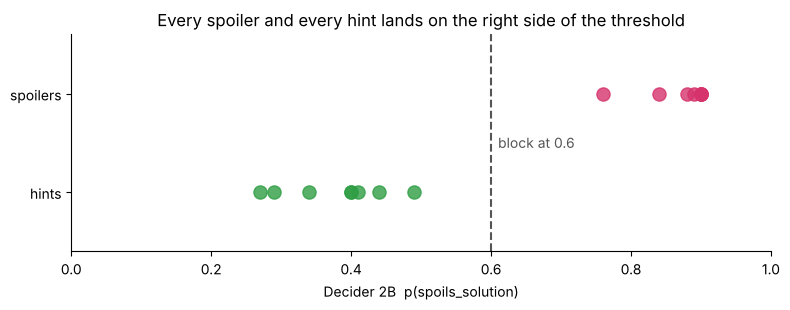

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.2))
for label, color, y in [("spoiler", "#d6336c", 1), ("hint", "#2f9e44", 0)]:
    xs = [r["p"] for r in rows if r["label"] == label]
    ax.scatter(xs, [y] * len(xs), s=90, color=color, alpha=0.8, label=f"{label}s ({len(xs)})")
ax.axvline(SPOIL_BLOCK, color="#555", linestyle="--")
ax.text(SPOIL_BLOCK + 0.01, 0.5, f"block at {SPOIL_BLOCK}", va="center", color="#555")
ax.set_xlim(0, 1); ax.set_ylim(-0.6, 1.6); ax.set_yticks([0, 1]); ax.set_yticklabels(["hints", "spoilers"])
ax.set_xlabel("Decider 2B  p(spoils_solution)")
ax.set_title("Every spoiler and every hint lands on the right side of the threshold")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## Takeaways

- **Same accuracy, zero tokens.** Decider matched the Bedrock judge on all 16 cases while costing no Bedrock tokens, because it runs locally. A tutor checks every reply, so that saving grows with every conversation.
- **Wide margin.** Spoilers scored 0.76 and up, hints 0.49 and below, so the 0.60 threshold is not on a knife edge.
- **Honest latency.** About 2.1 s per check on a laptop CPU (the Bedrock judge was about 0.9 s). The ~115 ms AWS figure needs a GPU.
- **Reusable.** Any Strands agent that replies through a tool can use `patterns/socratic_guardrail/`: change the question text and the fallback, then pass `interventions=[SocraticGuardrail(...)]`.